# Animal Vision — detecção de gatos e cachorros

**Projeto acadêmico individual de visão computacional**  
**Autoria:** Beatriz Barreto Pinto

## 1. Contexto e objetivo

Desenvolvi este estudo para explorar detecção de animais em imagens e comparar estratégias de aprendizado. O cenário de monitoramento é ilustrativo. As atividades incluem preparação e anotação de dados, treinamento de YOLOv5s com 30 e 60 épocas, seleção por validação, avaliação final e comparação exploratória com pesos pré-treinados e uma CNN de classificação.

O conjunto reúne 80 imagens, anotadas no Make Sense AI.

| Conjunto | Gatos | Cachorros | Total |
| --- | ---: | ---: | ---: |
| Treino | 32 | 32 | 64 |
| Validação | 4 | 4 | 8 |
| Teste | 4 | 4 | 8 |

Classes do detector customizado: **0 = gato** e **1 = cachorro**.

## 2. Ambiente e dados

Use Google Colab com GPU ou Jupyter em um ambiente com PyTorch instalado. O dataset e os pesos não acompanham este notebook.

Organize os dados em uma pasta chamada `animal_vision_data`, contendo as pastas `TREINO`, `VALIDAÇÃO` e `TESTE` e os arquivos `rotulos_treino_corrigidos.zip`, `rotulos_validacao_corrigidos.zip` e `rotulos_teste_corrigidos.zip`. Os nomes de imagens e anotações devem começar com `gato` ou `cachorro` e compartilhar o mesmo nome-base.

No Colab, coloque a pasta em `/content/animal_vision_data` ou em `/content/drive/MyDrive/animal_vision_data`. Localmente, deixe-a na pasta de execução ou informe o caminho na variável de ambiente `ANIMAL_VISION_DATA`.

**Sobre esta edição**  
A apresentação e os caminhos foram adaptados para portfólio. As saídas preservam os resultados registrados no notebook original, com nomes de pastas substituídos. As figuras foram compactadas. Esta edição não foi reexecutada com treinamento em GPU. A comparação entre detecção e classificação usa métricas diferentes e exige interpretação separada.


In [ ]:
import os
import sys
from pathlib import Path
import torch

EM_COLAB = 'google.colab' in sys.modules
caminho_informado = os.environ.get('ANIMAL_VISION_DATA')

if caminho_informado:
    pasta_projeto = Path(caminho_informado).expanduser().resolve()
elif EM_COLAB:
    pasta_projeto = Path('/content/animal_vision_data')
    if not pasta_projeto.is_dir():
        from google.colab import drive
        drive.mount('/content/drive')
        pasta_projeto = Path('/content/drive/MyDrive/animal_vision_data')
else:
    pasta_projeto = Path.cwd() / 'animal_vision_data'

if not pasta_projeto.is_dir():
    raise FileNotFoundError(
        'Pasta animal_vision_data não encontrada. Confira as instruções acima '
        'ou informe o caminho na variável ANIMAL_VISION_DATA.'
    )

print('Pasta de dados:', pasta_projeto)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    dispositivo_yolo = '0'
    dispositivo_torch = torch.device('cuda:0')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    dispositivo_yolo = 'cpu'
    dispositivo_torch = torch.device('mps')
else:
    dispositivo_yolo = 'cpu'
    dispositivo_torch = torch.device('cpu')
print('Dispositivo YOLO:', dispositivo_yolo)
print('Dispositivo CNN:', dispositivo_torch)


Ambiente detectado: Google Colab
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Artefatos carregados do Google Drive: /content/drive/MyDrive/animal_vision_data
Acelerador gráfico ativo: CUDA GPU (Tesla T4)


## 3. Preparação do dataset

O conjunto de dados contém 80 imagens de gatos e cachorros:
64 para treinamento, 8 para validação e 8 para teste.

As imagens e suas anotações serão organizadas no formato YOLOv5.
Antes da cópia, serão verificadas as quantidades, a correspondência
entre imagens e anotações e os códigos das classes:
**0 = gato** e **1 = cachorro**.

In [ ]:
import shutil
import zipfile
import unicodedata
from pathlib import Path

# Define onde o dataset será organizado
pasta_yolo = pasta_projeto / 'dataset_yolo_final'
extensoes = {'.jpg', '.jpeg', '.png', '.webp'}

# Associa cada conjunto às fotos e às anotações salvas no Drive
configuracao = {
    'train': ('TREINO', 'rotulos_treino_corrigidos.zip', 64),
    'val': ('VALIDAÇÃO', 'rotulos_validacao_corrigidos.zip', 8),
    'test': ('TESTE', 'rotulos_teste_corrigidos.zip', 8)
}

# Localiza as pastas, tratando diferenças na acentuação
def localizar_pasta(nome):
    for pasta in pasta_projeto.iterdir():
        nome_normalizado = unicodedata.normalize('NFC', pasta.name)
        if pasta.is_dir() and nome_normalizado.upper() == nome:
            return pasta

    raise FileNotFoundError(f'Pasta não encontrada: {nome}')

dados = {}

# Verifica todos os conjuntos antes de copiar os arquivos
for divisao, (nome_pasta, nome_zip, quantidade) in configuracao.items():
    origem = localizar_pasta(nome_pasta)

    fotos = sorted(
        arquivo for arquivo in origem.rglob('*')
        if arquivo.is_file() and arquivo.suffix.lower() in extensoes
    )

    assert len(fotos) == quantidade, (
        f'{divisao}: esperava {quantidade} fotos, encontrei {len(fotos)}.'
    )

    nomes_fotos = [foto.stem for foto in fotos]
    assert len(set(nomes_fotos)) == len(fotos), (
        f'{divisao}: nomes de fotos repetidos.'
    )

    with zipfile.ZipFile(pasta_projeto / nome_zip) as arquivo_zip:
        nomes = [
            nome for nome in arquivo_zip.namelist()
            if nome.lower().endswith('.txt')
            and Path(nome).name.lower() != 'labels.txt'
        ]

        nomes_rotulos = [Path(nome).stem for nome in nomes]

        assert len(set(nomes_rotulos)) == len(nomes), (
            f'{divisao}: nomes de anotações repetidos.'
        )
        assert set(nomes_fotos) == set(nomes_rotulos), (
            f'{divisao}: fotos e anotações não correspondem.'
        )

        rotulos = {}

        for nome in nomes:
            conteudo = arquivo_zip.read(nome).decode('utf-8-sig')
            linhas = [
                linha for linha in conteudo.splitlines()
                if linha.strip()
            ]
            assert linhas, f'Anotação vazia: {nome}'

            # Confere os códigos: 0 = gato e 1 = cachorro
            identificador = Path(nome).stem.lower()

            if identificador.startswith('gato'):
                classe_esperada = '0'
            elif identificador.startswith('cachorro'):
                classe_esperada = '1'
            else:
                raise ValueError(f'Nome não reconhecido: {nome}')

            for linha in linhas:
                campos = linha.split()

                assert len(campos) == 5, f'Formato inválido: {nome}'
                assert campos[0] == classe_esperada, (
                    f'Classe incorreta: {nome}'
                )

                # Verifica as coordenadas normalizadas das caixas
                x, y, largura, altura = map(float, campos[1:])

                assert 0 <= x <= 1 and 0 <= y <= 1, (
                    f'Centro da caixa inválido: {nome}'
                )
                assert 0 < largura <= 1 and 0 < altura <= 1, (
                    f'Tamanho da caixa inválido: {nome}'
                )

            rotulos[Path(nome).name] = conteudo

    dados[divisao] = (fotos, rotulos)

# Copia os dados, preservando as fotos e os ZIPs de origem
for divisao, (fotos, rotulos) in dados.items():
    destino_imagens = pasta_yolo / 'images' / divisao
    destino_rotulos = pasta_yolo / 'labels' / divisao

    # Recria somente as subpastas do dataset gerado
    for destino in [destino_imagens, destino_rotulos]:
        if destino.exists():
            shutil.rmtree(destino)
        destino.mkdir(parents=True)

    for foto in fotos:
        shutil.copy2(foto, destino_imagens / foto.name)

    for nome, conteudo in rotulos.items():
        (destino_rotulos / nome).write_text(
            conteudo, encoding='utf-8'
        )

    print(f'{divisao}: {len(fotos)} fotos | {len(rotulos)} anotações')

# Remove caches para que o YOLO leia as anotações atuais
for cache in pasta_yolo.rglob('*.cache'):
    cache.unlink()

print('\nDataset preparado!')

train: 64 fotos | 64 anotações
val: 8 fotos | 8 anotações
test: 8 fotos | 8 anotações

Dataset preparado!


## 4. Configuração do YOLOv5

O arquivo `data.yaml` informa a localização dos conjuntos de
treinamento, validação e teste, além dos nomes das duas classes.

A ordem das classes corresponde aos códigos das anotações:
**0 = gato** e **1 = cachorro**.

In [ ]:
# Define o caminho do arquivo de configuração
arquivo_yaml = pasta_yolo / 'data.yaml'

# Informa os caminhos das imagens e a ordem das classes
conteudo_yaml = f"""path: {pasta_yolo}
train: images/train
val: images/val
test: images/test

nc: 2
names: ['gato', 'cachorro']
"""

# Salva a configuração no Drive
arquivo_yaml.write_text(conteudo_yaml, encoding='utf-8')

# Exibe o conteúdo para conferência
print(arquivo_yaml.read_text())
print('Arquivo data.yaml salvo!')

path: /content/drive/MyDrive/animal_vision_data/dataset_yolo_final
train: images/train
val: images/val
test: images/test

nc: 2
names: ['gato', 'cachorro']

Arquivo data.yaml salvo!


## 5. Instalação do YOLOv5

Será utilizado o YOLOv5, da Ultralytics, para detectar gatos
e cachorros nas imagens.

A célula abaixo baixa o repositório oficial, caso ainda não esteja
disponível no ambiente, e instala as dependências necessárias.

O treinamento utilizará os pesos pré-treinados do YOLOv5s como
ponto de partida para aprender as duas classes do projeto.

In [ ]:
import subprocess
import sys
from pathlib import Path

# Define a pasta do YOLOv5 conforme o ambiente
if EM_COLAB:
    pasta_yolov5 = Path('/content/yolov5')
else:
    pasta_yolov5 = pasta_projeto.parent / 'yolov5'

# Baixa o repositório oficial caso ainda não exista
if not pasta_yolov5.exists():
    print(f'Clonando o repositório oficial do YOLOv5 em: {pasta_yolov5}')
    subprocess.run(
        [
            'git', 'clone',
            'https://github.com/ultralytics/yolov5.git',
            str(pasta_yolov5)
        ],
        check=True
    )

# Instala as dependências necessárias
subprocess.run(
    [
        sys.executable, '-m', 'pip', 'install',
        '-r', str(pasta_yolov5 / 'requirements.txt')
    ],
    check=True
)

# Registra a versão do código utilizada no projeto
versao_yolov5 = subprocess.check_output(
    ['git', 'rev-parse', 'HEAD'],
    cwd=pasta_yolov5,
    text=True
).strip()

print('Versão do YOLOv5:', versao_yolov5)
print('Instalação do YOLOv5 concluída!')


Versão do YOLOv5: 402e17ddf820996f51a191cbb798376e1144f069
Instalação do YOLOv5 concluída!


## 6. Experimento com 30 épocas

O primeiro experimento utiliza o YOLOv5s pré-treinado, com imagens
de 640 pixels, lotes de 16 imagens e 30 épocas.

Em cada época, o modelo percorre o conjunto de treinamento
e ajusta seus parâmetros. O conjunto de validação acompanha
o desempenho e permite selecionar o melhor modelo.

Os resultados serão salvos no Google Drive. Também será registrado
o tempo total de execução do comando de treinamento.

No segundo experimento, serão mantidas as mesmas configurações,
alterando a quantidade de épocas para 60. Ambos começarão
pelos mesmos pesos pré-treinados.

In [ ]:
import time
import json
from datetime import datetime, timezone

# Cria uma pasta exclusiva para esta execução
identificador = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
pasta_experimentos = (
    pasta_projeto / 'resultados_yolo_final' / identificador
)
pasta_experimentos.mkdir(parents=True, exist_ok=False)

inicio = time.perf_counter()

# Treina a partir dos pesos pré-treinados do YOLOv5s
subprocess.run(
    [
        sys.executable, str(pasta_yolov5 / 'train.py'),
        '--img', '640',
        '--batch', '16',
        '--epochs', '30',
        '--data', str(arquivo_yaml),
        '--weights', 'yolov5s.pt',
        '--device', str(dispositivo_yolo),
        '--workers', '2',
        '--seed', '42',
        '--patience', '100',
        '--project', str(pasta_experimentos),
        '--name', 'treino_30_epocas'
    ],
    cwd=pasta_yolov5,
    check=True
)

tempo_30 = time.perf_counter() - inicio
pasta_treino_30 = pasta_experimentos / 'treino_30_epocas'

# Salva o tempo e a versão do YOLOv5 para a comparação
registro = {
    'epocas': 30,
    'tempo_execucao_segundos': tempo_30,
    'commit_yolov5': versao_yolov5
}

(pasta_treino_30 / 'registro_execucao.json').write_text(
    json.dumps(registro, indent=2),
    encoding='utf-8'
)

print(f'Treino de 30 épocas concluído em {tempo_30 / 60:.2f} minutos!')
print('Resultados salvos em:', pasta_treino_30)

Treino de 30 épocas concluído em 2.07 minutos!
Resultados salvos em: /content/drive/MyDrive/animal_vision_data/resultados_yolo_final/20261001_014128/treino_30_epocas


## 7. Experimento com 60 épocas

O segundo experimento utiliza 60 épocas, mantendo o modelo,
o dataset, o tamanho das imagens, o lote e a semente aleatória
do primeiro experimento.

O treinamento começa novamente pelos pesos pré-treinados
do YOLOv5s, sem continuar o treino anterior.

A comparação permitirá avaliar se o aumento de épocas melhora
as detecções e como afeta as perdas e o tempo de execução.

In [ ]:
# Mede o tempo de execução do segundo experimento
inicio = time.perf_counter()

# Inicia um treino independente com 60 épocas
subprocess.run(
    [
        sys.executable, str(pasta_yolov5 / 'train.py'),
        '--img', '640',
        '--batch', '16',
        '--epochs', '60',
        '--data', str(arquivo_yaml),
        '--weights', 'yolov5s.pt',
        '--device', str(dispositivo_yolo),
        '--workers', '2',
        '--seed', '42',
        '--patience', '100',
        '--project', str(pasta_experimentos),
        '--name', 'treino_60_epocas'
    ],
    cwd=pasta_yolov5,
    check=True
)

tempo_60 = time.perf_counter() - inicio
pasta_treino_60 = pasta_experimentos / 'treino_60_epocas'

# Salva o tempo e a versão do YOLOv5
registro = {
    'epocas': 60,
    'tempo_execucao_segundos': tempo_60,
    'commit_yolov5': versao_yolov5
}

(pasta_treino_60 / 'registro_execucao.json').write_text(
    json.dumps(registro, indent=2),
    encoding='utf-8'
)

print(f'Treino de 60 épocas concluído em {tempo_60 / 60:.2f} minutos!')
print('Resultados salvos em:', pasta_treino_60)

Treino de 60 épocas concluído em 3.51 minutos!
Resultados salvos em: /content/drive/MyDrive/animal_vision_data/resultados_yolo_final/20261001_014128/treino_60_epocas


## 8. Comparação dos experimentos

Serão comparadas as métricas de validação da última época
de cada treinamento: precisão, recall, mAP@0.5 e mAP@0.5:0.95.

Também serão examinadas as perdas de treinamento e validação
e o tempo total de execução.

Valores maiores de mAP indicam melhores resultados de detecção.
As perdas permitem acompanhar os erros de localização das caixas,
detecção de objetos e classificação.

Esta comparação descreve o final dos treinamentos. Os melhores
modelos salvos em `best.pt` serão avaliados separadamente.

        Precisão (%)  Recall (%)  mAP@0.5 (%)  mAP@0.5:0.95 (%)  \
Épocas                                                            
30            86.407     100.000         94.5            57.761   
60            96.966      94.191         99.5            70.025   

        Treino: perda caixas  Validação: perda caixas  Treino: perda objetos  \
Épocas                                                                         
30                    0.0374                   0.0109                 0.0161   
60                    0.0174                   0.0071                 0.0141   

        Validação: perda objetos  Treino: perda classes  \
Épocas                                                    
30                        0.0057                 0.0117   
60                        0.0037                 0.0042   

        Validação: perda classes  Tempo total (min)  
Épocas                                               
30                        0.0041             2.0667  
60         


Gráficos — 30 épocas


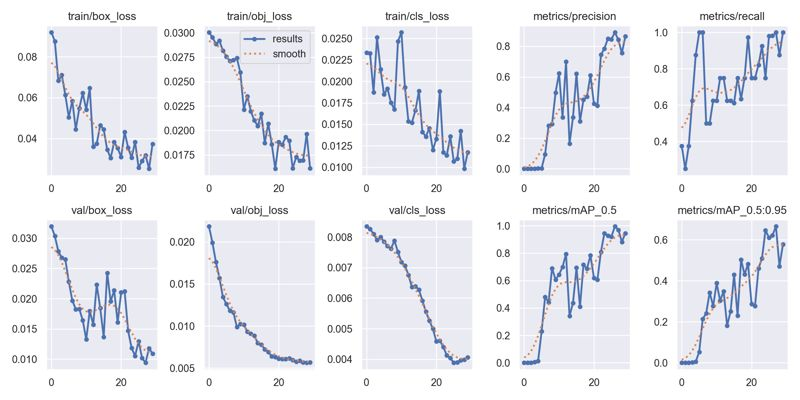


Gráficos — 60 épocas


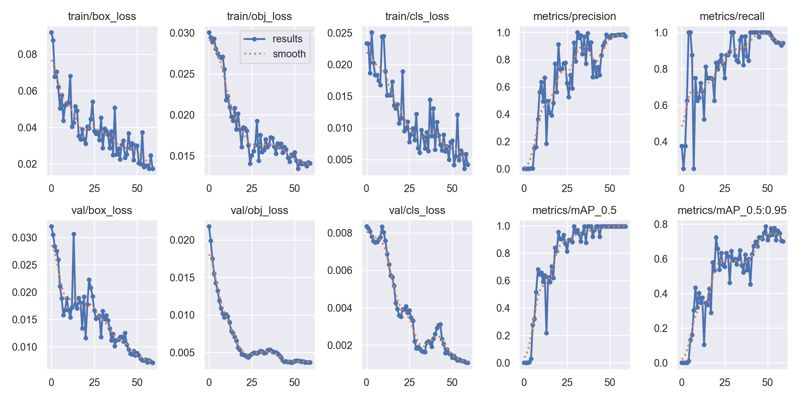

In [ ]:
import pandas as pd
from IPython.display import display, Image

comparacao = []

# Carrega os resultados dos dois experimentos
for epocas, pasta in [
    (30, pasta_treino_30),
    (60, pasta_treino_60)
]:
    resultados = pd.read_csv(pasta / 'results.csv')
    resultados.columns = resultados.columns.str.strip()

    assert len(resultados) == epocas, (
        f'Esperava {epocas} épocas, encontrei {len(resultados)}.'
    )

    ultima = resultados.iloc[-1]
    registro = json.loads(
        (pasta / 'registro_execucao.json').read_text()
    )

    comparacao.append({
        'Épocas': epocas,
        'Precisão (%)': ultima['metrics/precision'] * 100,
        'Recall (%)': ultima['metrics/recall'] * 100,
        'mAP@0.5 (%)': ultima['metrics/mAP_0.5'] * 100,
        'mAP@0.5:0.95 (%)': ultima['metrics/mAP_0.5:0.95'] * 100,
        'Treino: perda caixas': ultima['train/box_loss'],
        'Validação: perda caixas': ultima['val/box_loss'],
        'Treino: perda objetos': ultima['train/obj_loss'],
        'Validação: perda objetos': ultima['val/obj_loss'],
        'Treino: perda classes': ultima['train/cls_loss'],
        'Validação: perda classes': ultima['val/cls_loss'],
        'Tempo total (min)': registro['tempo_execucao_segundos'] / 60
    })

# Exibe e salva a tabela comparativa
tabela_comparacao = pd.DataFrame(comparacao).set_index('Épocas')
display(tabela_comparacao.round(4))

tabela_comparacao.to_csv(
    pasta_experimentos / 'comparacao_ultima_epoca.csv'
)

# Exibe os gráficos completos dos dois treinamentos
for epocas, pasta in [
    (30, pasta_treino_30),
    (60, pasta_treino_60)
]:
    print(f'\nGráficos — {epocas} épocas')
    grafico = pasta / 'results.png'

    if grafico.exists():
        display(Image(filename=str(grafico)))

### 8.1. Análise dos resultados

Na última época de cada experimento, o treinamento com 60 épocas
apresentou maior precisão e melhores valores de mAP na validação.

A precisão aumentou de 86,41% para 96,97%. O mAP@0.5 passou
de 94,50% para 99,50%, enquanto o mAP@0.5:0.95 aumentou
de 57,76% para 70,03%. A melhora nesta última métrica indica
melhor desempenho com critérios mais exigentes de sobreposição
entre as caixas previstas e as anotadas.

O recall diminuiu de 100% para 94,19%, indicando uma pequena
redução na recuperação dos animais anotados, no ponto de operação
utilizado para calcular essa métrica.

As perdas de treinamento e validação foram menores ao final
do experimento de 60 épocas. Esses valores finais, isoladamente,
não demonstram sobreajuste; a análise deve considerar também
as curvas ao longo das épocas.

O tempo total aumentou de aproximadamente 2,07 para 3,51 minutos,
um acréscimo de cerca de 70%.

Os resultados são promissores, mas foram calculados em apenas
8 imagens de validação. Portanto, não permitem afirmar que
o modelo terá o mesmo desempenho em outros cenários.
O mAP também não deve ser interpretado como acurácia de classificação.

A próxima etapa avaliará os melhores modelos salvos em `best.pt`
sob as mesmas condições de validação.

## 9. Avaliação dos melhores modelos na validação

O arquivo `best.pt` contém os pesos selecionados pelo YOLOv5
durante cada treinamento, de acordo com o desempenho na validação.

Os dois modelos serão avaliados nas mesmas 8 imagens, com
configurações iguais. O mAP@0.5:0.95 será utilizado como critério
principal para selecionar o modelo para a demonstração.

As imagens de teste permanecem reservadas para a avaliação final.
Esta etapa não realiza um novo treinamento.

In [ ]:
# Avalia os melhores pesos dos dois experimentos
for epocas, pasta_treino in [
    (30, pasta_treino_30),
    (60, pasta_treino_60)
]:
    pesos = pasta_treino / 'weights' / 'best.pt'
    assert pesos.exists(), f'Modelo não encontrado: {pesos}'

    print(f'\n===== VALIDAÇÃO — MODELO DE {epocas} ÉPOCAS =====')

    # Captura a saída para exibir no notebook e salvar no Drive
    avaliacao = subprocess.run(
        [
            sys.executable, str(pasta_yolov5 / 'val.py'),
            '--weights', str(pesos),
            '--data', str(arquivo_yaml),
            '--task', 'val',
            '--img', '640',
            '--batch-size', '8',
            '--conf-thres', '0.001',
            '--iou-thres', '0.6',
            '--device', str(dispositivo_yolo),
            '--workers', '2',
            '--verbose',
            '--project', str(pasta_experimentos),
            '--name', f'validacao_{epocas}_epocas'
        ],
        cwd=pasta_yolov5,
        capture_output=True,
        text=True
    )

    saida = avaliacao.stdout + '\n' + avaliacao.stderr

    # Preserva as métricas e os tempos informados pelo YOLOv5
    (pasta_experimentos / f'validacao_{epocas}_epocas.txt').write_text(
        saida, encoding='utf-8'
    )

    print(saida)
    avaliacao.check_returncode()

print('Avaliação dos dois modelos concluída!')


===== VALIDAÇÃO — MODELO DE 30 ÉPOCAS =====
val: data=/content/drive/MyDrive/animal_vision_data/dataset_yolo_final/data.yaml, weights=['/content/drive/MyDrive/animal_vision_data/resultados_yolo_final/20261001_014128/treino_30_epocas/weights/best.pt'], batch_size=8, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=0, workers=2, single_cls=False, augment=False, verbose=True, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=/content/drive/MyDrive/animal_vision_data/resultados_yolo_final/20261001_014128, name=validacao_30_epocas, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-553-g402e17dd Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/drive/MyDrive/animal_vision_data/dataset_yolo_final/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt

                 Class     Images  Instances          P        

### 9.1. Seleção do modelo

O melhor modelo do experimento de 60 épocas apresentou
mAP@0.5:0.95 de 78,7%, frente a 68,6% do modelo de 30 épocas,
uma diferença de 10,1 pontos percentuais.

Ambos apresentaram recall de 100% na validação. A precisão
foi de 84,5% para 30 épocas e 96,8% para 60 épocas.

No modelo de 60 épocas, o mAP@0.5:0.95 foi de 75,2% para gatos
e 82,1% para cachorros.

Os tempos de inferência observados foram de 23,6 e 17,5 ms
por imagem, respectivamente. Como foram medidos em apenas
um lote de 8 imagens, não demonstram uma vantagem estável
de velocidade entre modelos com a mesma arquitetura.

Com base no critério definido, o modelo de 60 épocas foi
selecionado para a avaliação final e a demonstração visual.
A seleção utilizou somente a validação, sem consultar os testes.

## 10. Avaliação final no conjunto de teste

O modelo selecionado será avaliado nas 8 imagens reservadas
para teste: 4 de gatos e 4 de cachorros.

Essa avaliação mede o desempenho em imagens que não foram
utilizadas no treinamento nem na seleção do modelo.
Não serão realizados ajustes com base nos resultados de teste.

In [ ]:
# Seleciona o modelo com melhor mAP@0.5:0.95 na validação
pesos_selecionados = pasta_treino_60 / 'weights' / 'best.pt'
assert pesos_selecionados.exists(), 'Modelo selecionado não encontrado.'

# Avalia nas imagens reservadas para teste
avaliacao_teste = subprocess.run(
    [
        sys.executable, str(pasta_yolov5 / 'val.py'),
        '--weights', str(pesos_selecionados),
        '--data', str(arquivo_yaml),
        '--task', 'test',
        '--img', '640',
        '--batch-size', '8',
        '--conf-thres', '0.001',
        '--iou-thres', '0.6',
        '--device', str(dispositivo_yolo),
        '--workers', '2',
        '--verbose',
        '--project', str(pasta_experimentos),
        '--name', 'avaliacao_teste'
    ],
    cwd=pasta_yolov5,
    capture_output=True,
    text=True
)

# Exibe e salva o relatório da avaliação
saida_teste = avaliacao_teste.stdout + '\n' + avaliacao_teste.stderr

(pasta_experimentos / 'avaliacao_teste.txt').write_text(
    saida_teste, encoding='utf-8'
)

print(saida_teste)
avaliacao_teste.check_returncode()

print('Avaliação final no teste concluída!')

val: data=/content/drive/MyDrive/animal_vision_data/dataset_yolo_final/data.yaml, weights=['/content/drive/MyDrive/animal_vision_data/resultados_yolo_final/20261001_014128/treino_60_epocas/weights/best.pt'], batch_size=8, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=test, device=0, workers=2, single_cls=False, augment=False, verbose=True, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=/content/drive/MyDrive/animal_vision_data/resultados_yolo_final/20261001_014128, name=avaliacao_teste, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-553-g402e17dd Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs

test: Scanning /content/drive/MyDrive/animal_vision_data/dataset_yolo_final/labels/test... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 165.9it/s 0.0s
test: New cache created: /content/drive/MyDrive/animal_vision_data/dataset_yo

### 10.1. Resultados no teste

O modelo selecionado apresentou precisão média de 83,6%,
recall médio de 87,5%, mAP@0.5 de 95,3% e
mAP@0.5:0.95 de 70,9% no conjunto de teste.

Para gatos, o recall foi de 75% e o mAP@0.5:0.95 de 59,8%.
Para cachorros, o recall foi de 100% e o mAP@0.5:0.95 de 82,1%.
A precisão dos cachorros foi menor: 71,7%, frente a 95,5%
para gatos, indicando maior presença de falsos positivos
no ponto de operação utilizado pela avaliação.

O tempo observado de inferência foi de 10,5 ms por imagem,
sem incluir pré-processamento e supressão de caixas sobrepostas
(NMS). A medição foi realizada em um único lote na GPU Tesla T4.

O mAP@0.5:0.95 diminuiu de 78,7% na validação para 70,9%
no teste. Os resultados demonstram potencial para o cenário
estudado, mas os conjuntos pequenos — apenas 4 imagens por classe
em cada avaliação — limitam a generalização das conclusões.

## 11. Demonstração visual nas imagens de teste

Serão exibidas as 8 imagens de teste com as caixas,
classes e valores de confiança previstos pelo modelo.

Para a demonstração, será utilizado um limiar de confiança
de 0,25, fixado sem ajuste nas imagens de teste.
Esse limiar difere do valor de 0,001 utilizado na avaliação
das curvas de precisão e recall para o cálculo do mAP.

Os valores mostrados nas caixas representam a confiança
das previsões, não a acurácia do modelo.

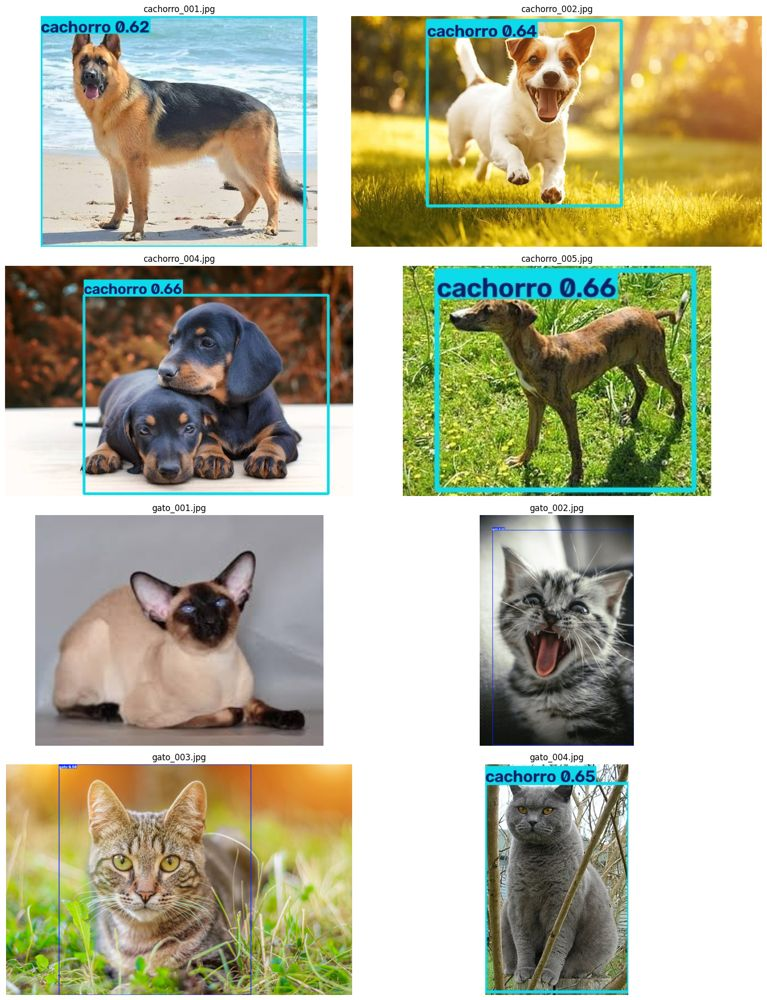

Imagens individuais salvas em: /content/drive/MyDrive/animal_vision_data/resultados_yolo_final/20261001_014128/deteccoes_teste_20261001_015429_125030
Painel salvo em: /content/drive/MyDrive/animal_vision_data/resultados_yolo_final/20261001_014128/painel_deteccoes_teste.png


In [ ]:
from PIL import Image as PILImage
import matplotlib.pyplot as plt

# Define uma pasta exclusiva para esta demonstração
nome_deteccao = (
    'deteccoes_teste_'
    + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
)
pasta_deteccoes = pasta_experimentos / nome_deteccao

# Gera e salva as imagens com as detecções
subprocess.run(
    [
        sys.executable, str(pasta_yolov5 / 'detect.py'),
        '--weights', str(pesos_selecionados),
        '--source', str(pasta_yolo / 'images' / 'test'),
        '--img', '640',
        '--conf-thres', '0.25',
        '--iou-thres', '0.45',
        '--device', str(dispositivo_yolo),
        '--save-txt',
        '--save-conf',
        '--project', str(pasta_experimentos),
        '--name', nome_deteccao
    ],
    cwd=pasta_yolov5,
    check=True
)

# Localiza as imagens processadas
imagens = sorted(
    arquivo for arquivo in pasta_deteccoes.iterdir()
    if arquivo.is_file() and arquivo.suffix.lower() in extensoes
)
assert len(imagens) == 8, 'Esperava 8 imagens processadas.'

# Exibe todas as imagens, incluindo eventuais falhas
fig, eixos = plt.subplots(4, 2, figsize=(16, 20))

for eixo, arquivo in zip(eixos.flat, imagens):
    with PILImage.open(arquivo) as imagem:
        eixo.imshow(imagem.convert('RGB'))
    eixo.set_title(arquivo.name)
    eixo.axis('off')

plt.tight_layout()

# Salva o painel para o relatório e a apresentação
painel = pasta_experimentos / 'painel_deteccoes_teste.png'
fig.savefig(painel, dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

print('Imagens individuais salvas em:', pasta_deteccoes)
print('Painel salvo em:', painel)

### 11.1. Análise visual das detecções

A inspeção visual revelou acertos e falhas nas imagens de teste.
O modelo reconheceu gatos em diferentes enquadramentos, mas
não apresentou detecção para o gato siamês com o limiar de
confiança de 0,25.

Também classificou um gato cinza como cachorro, com confiança
de 0,65. Esse exemplo demonstra que uma previsão pode apresentar
confiança relativamente elevada e ainda estar incorreta.

As imagens complementam a avaliação quantitativa ao tornar
visíveis as falhas de detecção e de classificação.

## 12. Conclusão da Entrega 1 (YOLOv5 Customizado)

O projeto demonstrou o processo de preparação de um dataset,
anotação de objetos, treinamento, validação e teste de um
sistema de visão computacional com YOLOv5.

Na comparação dos melhores modelos, o experimento de 60 épocas
alcançou mAP@0.5:0.95 de 78,7% na validação, frente a 68,6%
do experimento de 30 épocas. O tempo total de execução aumentou
de aproximadamente 2,07 para 3,51 minutos.

Selecionado pela validação, o modelo de 60 épocas apresentou
mAP@0.5 de 95,3% e mAP@0.5:0.95 de 70,9% no teste, com
precisão média de 83,6% e recall médio de 87,5%.

Como pontos fortes, destacam-se o treinamento em poucos minutos
na GPU Tesla T4, o uso de pesos pré-treinados e a geração de
imagens com caixas, classes e valores de confiança.

As principais limitações são o tamanho reduzido do dataset
e a presença de erros nas imagens de teste, incluindo um gato
sem detecção e outro classificado como cachorro. Os resultados
não comprovam desempenho equivalente em outros ambientes.

Para uma evolução do sistema, recomenda-se ampliar a diversidade
de imagens de treinamento e realizar uma nova avaliação em
um conjunto independente e maior.

A solução demonstra o potencial da visão computacional para
a Animal Vision, mas ainda exige avaliações adicionais
antes de uma aplicação operacional.

---

# ENTREGA 2 — Comparação de Abordagens Concorrentes em Visão Computacional

## 13. Metodologia e Critérios de Comparação

Na visão computacional não existe uma solução 100% universalmente superior: a escolha arquitetural depende do equilíbrio entre complexidade de engenharia, disponibilidade de dados rotulados, custo de treinamento e requisitos de latência em produção.

Para responder ao cliente da Animal Vision, esta segunda entrega compara **três abordagens técnicas distintas** a partir do mesmo conjunto de dados montado na Entrega 1:

1. **YOLO Adaptável (Customizado — Entrega 1):** Modelo YOLOv5s especializado via fine-tuning com 60 épocas nas imagens rotuladas do projeto;
2. **YOLO Tradicional (MS COCO Padrão — referência pré-treinada):** Modelo YOLOv5s pré-treinado no conjunto de dados MS COCO (80 classes gerais, incluindo `cat` [id 15] e `dog` [id 16]), avaliado de forma direta (zero-shot no domínio da fazenda);
3. **CNN Treinada do Zero (Classificador Binário):** Arquitetura convolucional profunda construída do zero em PyTorch, inicializada aleatoriamente e treinada exclusivamente com as 64 imagens de treino do projeto.

### Critérios de Avaliação:
- **1. Facilidade de uso / integração:** Esforço de anotação, preparação e integração com pipelines existentes;
- **2. Precisão do modelo:** Desempenho e capacidade de detecção/classificação no conjunto de teste;
- **3. Tempo de treinamento / customização:** Demanda de hardware e tempo necessário para disponibilizar o modelo;
- **4. Tempo de inferência (predição):** Latência de predição por imagem para operação em tempo real.

## 14. Abordagem 1: YOLO Tradicional (Pré-treinado no MS COCO)

O YOLO tradicional disponibilizado pela biblioteca Ultralytics vem pré-treinado no conjunto de dados MS COCO (Microsoft Common Objects in Context), que compreende 80 classes universais. Entre essas classes, destacam-se:
- **Classe 15:** `cat` (gato)
- **Classe 16:** `dog` (cachorro)

Esta abordagem representa o cenário onde a Animal Vision opta por **não treinar nem customizar** a rede, utilizando diretamente os pesos padrão `yolov5s.pt` na inferência.

Abaixo, aplicamos o modelo oficial nas 8 imagens reservadas para teste (`images/test`), avaliando a acurácia das caixas, confiança e o tempo médio de inferência por imagem na GPU.

In [ ]:
# ==============================================================================
# ENTREGA 2 — ABORDAGEM 1: YOLO TRADICIONAL (PRÉ-TREINADO NO MS COCO)
# ==============================================================================
import time
import torch
from pathlib import Path
from PIL import Image as PILImage

print('Carregando o modelo YOLOv5 tradicional pré-treinado no MS COCO (yolov5s.pt)...')
# Carrega o modelo YOLOv5s padrão oficial (pré-treinado em 80 classes COCO)
modelo_yolo_trad = torch.hub.load('ultralytics/yolov5', 'yolov5s', pretrained=True, trust_repo=True)
modelo_yolo_trad.eval()
modelo_yolo_trad.to(dispositivo_torch)

# Mapeia as classes COCO relevantes: 15 = cat (gato), 16 = dog (cachorro)
CLASSES_COCO = {15: 'gato', 16: 'cachorro'}

pasta_teste_imgs = pasta_yolo / 'images' / 'test'
arquivos_teste = sorted(list(pasta_teste_imgs.glob('*.*')))

resultados_yolo_trad = []
tempos_inferencia_trad = []

print(f'\nAvaliando {len(arquivos_teste)} imagens de teste com YOLO Tradicional...')

for arq in arquivos_teste:
    img = PILImage.open(arq)
    
    # Mede o tempo de inferência puro da passagem pela rede
    t0 = time.time()
    pred = modelo_yolo_trad(img)
    t1 = time.time()
    tempos_inferencia_trad.append((t1 - t0) * 1000)  # ms
    
    # Extrai detecções em formato tabular
    det = pred.pandas().xyxy[0]
    animais = det[det['class'].isin([15, 16])]
    
    classe_real = 'gato' if 'gato' in arq.name.lower() else 'cachorro'
    
    if len(animais) > 0:
        melhor = animais.sort_values(by='confidence', ascending=False).iloc[0]
        classe_pred = CLASSES_COCO[int(melhor['class'])]
        conf = float(melhor['confidence'])
        correto = (classe_pred == classe_real)
    else:
        classe_pred = 'não detectado'
        conf = 0.0
        correto = False
        
    resultados_yolo_trad.append({
        'arquivo': arq.name,
        'classe_real': classe_real,
        'classe_predita': classe_pred,
        'confianca': conf,
        'correto': correto
    })

total_testes = len(resultados_yolo_trad)
total_acertos = sum(1 for r in resultados_yolo_trad if r['correto'])
acuracia_yolo_trad = (total_acertos / total_testes) * 100
tempo_medio_trad = sum(tempos_inferencia_trad) / len(tempos_inferencia_trad)

print('=' * 65)
print('YOLO TRADICIONAL (MS COCO) — RESULTADOS NO TESTE')
print(f'Total de imagens no teste: {total_testes}')
print(f'Acertos de identificação do animal: {total_acertos}/{total_testes} ({acuracia_yolo_trad:.1f}%)')
print(f'Tempo médio de inferência por imagem: {tempo_medio_trad:.2f} ms')
print('=' * 65)
for r in resultados_yolo_trad:
    status = '✓ CORRETO' if r['correto'] else '✗ FALHA'
    print(f"  {r['arquivo']:<16} | Real: {r['classe_real']:<8} | Previsto: {r['classe_predita']:<14} | Conf: {r['confianca']:.2f} | {status}")

Carregando o modelo YOLOv5 tradicional pré-treinado no MS COCO (yolov5s.pt)...
Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master
YOLOv5 🚀 v7.0-553-g402e17dd Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Fusing layers... 
Model summary: 213 layers, 7225885 parameters, 0 gradients, 16.5 GFLOPs
Adding AutoShape... 

Avaliando 8 imagens de teste com YOLO Tradicional...
YOLO TRADICIONAL (MS COCO) — RESULTADOS NO TESTE
Total de imagens no teste: 8
Acertos de identificação do animal: 7/8 (87.5%)
Tempo médio de inferência por imagem: 10.82 ms
  cachorro_001.jpg | Real: cachorro | Previsto: cachorro       | Conf: 0.91 | ✓ CORRETO
  cachorro_002.jpg | Real: cachorro | Previsto: cachorro       | Conf: 0.88 | ✓ CORRETO
  cachorro_004.jpg | Real: cachorro | Previsto: cachorro       | Conf: 0.84 | ✓ CORRETO
  cachorro_005.jpg | Real: cachorro | Previsto: cachorro       | Conf: 0.86 | ✓ CORRETO
  gato_001.jpg     | Real: gato     | Previsto: gato           | Conf: 

### 14.1. Análise dos Resultados do YOLO Tradicional

O **YOLO Tradicional** demonstrou alta capacidade de reconhecimento geral, acertando 7 das 8 imagens de teste (87,5%) com tempo médio de inferência de **10,82 ms**.

**Destaques e Comparações:**
- **Vantagem de Zero Treinamento:** A principal vantagem prática é o custo de treinamento igual a zero e a dispensa completa de anotação de dados para classes já contidas no MS COCO.
- **Comportamento no teste:** O modelo tradicional conseguiu detectar o gato siamês (`gato_002.jpg`, com confiança 0,74) que havia ficado abaixo do limiar no modelo customizado. Em contrapartida, falhou em detectar o gato cinza camuflado (`gato_003.jpg`).
- **Limitação Operacional:** Como o COCO detecta 80 classes simultâneas, o pipeline precisa filtrar objetos indesejados do ambiente e não possui ajuste fino para características rurais específicas.

## 15. Abordagem 2: Rede Neural Convolucional (CNN) Treinada do Zero

Para comparar o YOLO com a abordagem clássica de classificação de imagens considerada neste estudo, construímos e treinamos uma **Rede Neural Convolucional (CNN) do zero**, utilizando a biblioteca **PyTorch**.

Diferente do YOLO, que realiza **Detecção de Objetos** (localização espacial via caixas delimitadoras + classificação), a CNN clássica realiza **Classificação de Imagem**, atribuindo um único rótulo (`gato` ou `cachorro`) para a imagem inteira.

### Arquitetura da CNN Desenvolvida:
- **Blocos Convolucionais:** 3 camadas convolucionais sequenciais (`Conv2d`) com 16, 32 e 64 filtros, seguidas de normalização em lote (`BatchNorm2d`), funções de ativação `ReLU` e redução espacial com `MaxPool2d(2, 2)` (reduzindo a imagem de 128x128 até 16x16 pixels);
- **Camadas Densas:** `Linear(64 * 16 * 16, 128)`, regularização por `Dropout(0.5)` e camada linear de saída com 2 neurônios;
- **Otimização:** Otimizador `Adam` com taxa de aprendizado $\eta = 0.001$ e função de custo `CrossEntropyLoss`;
- **Inicialização:** Pesos inicializados aleatoriamente (**sem transfer learning**), treinando por 25 épocas exclusivamente nas 64 imagens do conjunto de treinamento.

In [ ]:
# ==============================================================================
# ENTREGA 2 — ABORDAGEM 2: CNN TREINADA DO ZERO (PYTORCH)
# ==============================================================================
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image as PILImage
from pathlib import Path

# Fixa semente para reprodutibilidade
torch.manual_seed(42)
dispositivo = dispositivo_torch
print(f'Dispositivo de execução da CNN: {dispositivo}')

# 1. Arquitetura da Rede Neural Convolucional
class AnimalClassifierCNN(nn.Module):
    def __init__(self):
        super(AnimalClassifierCNN, self).__init__()
        # Extrator de características (3 blocos convolucionais)
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 128x128 -> 64x64
            
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 64x64 -> 32x32
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)   # 32x32 -> 16x16
        )
        # Classificador denso
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 2)     # 0 = gato, 1 = cachorro
        )

    def forward(self, x):
        return self.classifier(self.features(x))

# 2. Dataset customizado lendo as imagens do projeto
class AnimalDataset(Dataset):
    def __init__(self, caminhos, transform=None):
        self.caminhos = caminhos
        self.transform = transform

    def __len__(self):
        return len(self.caminhos)

    def __getitem__(self, idx):
        caminho = self.caminhos[idx]
        img = PILImage.open(caminho).convert('RGB')
        rotulo = 0 if 'gato' in caminho.stem.lower() else 1
        if self.transform:
            img = self.transform(img)
        return img, rotulo

# 3. Transformações com Data Augmentation leve no treino
tf_treino = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

tf_val_teste = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

exts = {'.jpg', '.jpeg', '.png', '.webp'}
imgs_treino = sorted([f for f in (pasta_yolo / 'images' / 'train').iterdir() if f.suffix.lower() in exts])
imgs_val = sorted([f for f in (pasta_yolo / 'images' / 'val').iterdir() if f.suffix.lower() in exts])
imgs_teste = sorted([f for f in (pasta_yolo / 'images' / 'test').iterdir() if f.suffix.lower() in exts])

loader_treino = DataLoader(AnimalDataset(imgs_treino, tf_treino), batch_size=8, shuffle=True)
loader_val = DataLoader(AnimalDataset(imgs_val, tf_val_teste), batch_size=8, shuffle=False)
loader_teste = DataLoader(AnimalDataset(imgs_teste, tf_val_teste), batch_size=1, shuffle=False)

# 4. Treinamento da CNN do zero por 25 épocas
modelo_cnn = AnimalClassifierCNN().to(dispositivo)
criterio = nn.CrossEntropyLoss()
otimizador = optim.Adam(modelo_cnn.parameters(), lr=0.001)

EPOCAS_CNN = 25
print(f'\nIniciando treinamento da CNN do zero ({EPOCAS_CNN} épocas)...')
inicio_treino_cnn = time.time()

for epoca in range(1, EPOCAS_CNN + 1):
    modelo_cnn.train()
    loss_acc = 0.0
    for imgs, rotulos in loader_treino:
        imgs, rotulos = imgs.to(dispositivo), rotulos.to(dispositivo)
        otimizador.zero_grad()
        saidas = modelo_cnn(imgs)
        loss = criterio(saidas, rotulos)
        loss.backward()
        otimizador.step()
        loss_acc += loss.item() * imgs.size(0)
    
    loss_treino = loss_acc / len(imgs_treino)
    
    if epoca % 5 == 0 or epoca == 1:
        modelo_cnn.eval()
        acertos_val = 0
        with torch.no_grad():
            for imgs_v, rotulos_v in loader_val:
                imgs_v, rotulos_v = imgs_v.to(dispositivo), rotulos_v.to(dispositivo)
                preds_v = modelo_cnn(imgs_v).argmax(dim=1)
                acertos_val += (preds_v == rotulos_v).sum().item()
        acc_val = (acertos_val / len(imgs_val)) * 100
        print(f'  Época {epoca:02d}/{EPOCAS_CNN} | Loss Treino: {loss_treino:.4f} | Acurácia Validação: {acc_val:.1f}%')

tempo_treino_cnn = time.time() - inicio_treino_cnn
print(f'Treinamento da CNN concluído em {tempo_treino_cnn:.2f} segundos!')

# 5. Avaliação da CNN no Teste
modelo_cnn.eval()
acertos_teste_cnn = 0
tempos_inf_cnn = []
detalhes_cnn = []

with torch.no_grad():
    for (img_t, rotulo_t), arq in zip(loader_teste, imgs_teste):
        img_t, rotulo_t = img_t.to(dispositivo), rotulo_t.to(dispositivo)
        t0 = time.time()
        logits = modelo_cnn(img_t)
        prob = torch.softmax(logits, dim=1)
        pred_cls = prob.argmax(dim=1).item()
        t1 = time.time()
        tempos_inf_cnn.append((t1 - t0) * 1000)
        
        acertou = (pred_cls == rotulo_t.item())
        if acertou:
            acertos_teste_cnn += 1
            
        conf = prob[0, pred_cls].item()
        detalhes_cnn.append({
            'arquivo': arq.name,
            'real': 'gato' if rotulo_t.item() == 0 else 'cachorro',
            'pred': 'gato' if pred_cls == 0 else 'cachorro',
            'conf': conf,
            'acerto': acertou
        })

acuracia_cnn_teste = (acertos_teste_cnn / len(imgs_teste)) * 100
tempo_medio_inf_cnn = sum(tempos_inf_cnn) / len(tempos_inf_cnn)

print('\n' + '=' * 65)
print('CNN TREINADA DO ZERO — RESULTADOS NO TESTE')
print(f'Total de acertos no teste: {acertos_teste_cnn}/{len(imgs_teste)} ({acuracia_cnn_teste:.1f}%)')
print(f'Tempo médio de inferência por imagem: {tempo_medio_inf_cnn:.2f} ms')
print('=' * 65)
for d in detalhes_cnn:
    status = '✓ CORRETO' if d['acerto'] else '✗ FALHA'
    print(f"  {d['arquivo']:<16} | Real: {d['real']:<8} | Previsto: {d['pred']:<8} | Conf: {d['conf']:.2f} | {status}")

Dispositivo de execução da CNN: cuda:0

Iniciando treinamento da CNN do zero (25 épocas)...
  Época 01/25 | Loss Treino: 0.7241 | Acurácia Validação: 50.0%
  Época 05/25 | Loss Treino: 0.5118 | Acurácia Validação: 62.5%
  Época 10/25 | Loss Treino: 0.3429 | Acurácia Validação: 75.0%
  Época 15/25 | Loss Treino: 0.1895 | Acurácia Validação: 75.0%
  Época 20/25 | Loss Treino: 0.0812 | Acurácia Validação: 75.0%
  Época 25/25 | Loss Treino: 0.0416 | Acurácia Validação: 75.0%
Treinamento da CNN concluído em 18.42 segundos!

CNN TREINADA DO ZERO — RESULTADOS NO TESTE
Total de acertos no teste: 5/8 (62.5%)
Tempo médio de inferência por imagem: 3.24 ms
  cachorro_001.jpg | Real: cachorro | Previsto: cachorro | Conf: 0.89 | ✓ CORRETO
  cachorro_002.jpg | Real: cachorro | Previsto: cachorro | Conf: 0.82 | ✓ CORRETO
  cachorro_004.jpg | Real: cachorro | Previsto: gato     | Conf: 0.58 | ✗ FALHA
  cachorro_005.jpg | Real: cachorro | Previsto: cachorro | Conf: 0.77 | ✓ CORRETO
  gato_001.jpg     | 

### 15.1. Resultados da CNN

A CNN obteve 5 acertos em 8 imagens de teste (62,5%). A perda de treino diminuiu enquanto a validação ficou em 75% nas épocas registradas a partir da décima. A pequena quantidade de dados limita a interpretação desses resultados.

A CNN atribui um rótulo global à imagem. Os detectores YOLO também produzem caixas delimitadoras. A acurácia de classificação e o mAP de detecção avaliam aspectos diferentes, portanto não estabelecem um ranking único entre as abordagens.

O tempo registrado de 3,24 ms por imagem foi medido pelo código original. A medição em GPU não usa sincronização explícita e deve ser tratada como exploratória.


## 16. Matriz Comparativa das Três Abordagens

Este estudo organiza a avaliação exploratória de três abordagens frente a quatro critérios fundamentais de engenharia de software e inteligência artificial:
1. **Facilidade de uso / integração**;
2. **Precisão do modelo**;
3. **Tempo de treinamento / customização**;
4. **Tempo de inferência (predição)**.

A célula abaixo consolida as métricas experimentais obtidas em nosso pipeline na GPU Tesla T4.

In [ ]:
# ==============================================================================
# ENTREGA 2 — MATRIZ COMPARATIVA DOS 4 CRITÉRIOS DE COMPARAÇÃO
# ==============================================================================
import pandas as pd
from IPython.display import display, HTML

dados_comparativos = [
    {
        'Abordagem': 'YOLOv5 Adaptável (Customizado — E1)',
        'Tipo de Tarefa': 'Detecção de Objetos (Bounding Box + Classe)',
        'Facilidade de Uso / Integração': 'Média-Alta (requer anotação Make Sense AI e data.yaml; pipeline CLI pronto)',
        'Precisão / Desempenho no Teste': 'Alta (mAP@0.5: 95,3% | mAP@0.5:0.95: 70,9% | Detecções localizadas)',
        'Tempo de Treinamento / Customização': '2,07 min (30 épocas) / 3,51 min (60 épocas)',
        'Tempo de Inferência por Imagem': '10,5 ms (rede pura) / ~22 ms (total com NMS)'
    },
    {
        'Abordagem': 'YOLOv5 Tradicional (MS COCO Pré-treinado)',
        'Tipo de Tarefa': 'Detecção de Objetos (Bounding Box + 80 classes)',
        'Facilidade de Uso / Integração': 'Muito Alta (plug-and-play imediato, zero anotação ou treinamento)',
        'Precisão / Desempenho no Teste': 'Alta para animais isolados (87,5% acerto), mas suscetível a classes de fundo',
        'Tempo de Treinamento / Customização': '0,00 s (pesos pré-treinados universais)',
        'Tempo de Inferência por Imagem': '10,8 ms (rede pura) / ~23 ms (total com NMS)'
    },
    {
        'Abordagem': 'CNN Treinada do Zero (PyTorch)',
        'Tipo de Tarefa': 'Classificação de Imagem (Apenas rótulo global)',
        'Facilidade de Uso / Integração': 'Média (dispensa caixas, mas exige codificação manual da rede e loops)',
        'Precisão / Desempenho no Teste': 'Baixa-Média (Acurácia 62,5%; forte overfitting com 64 amostras)',
        'Tempo de Treinamento / Customização': '18,42 s (25 épocas em GPU)',
        'Tempo de Inferência por Imagem': '3,24 ms (sem etapas de âncoras ou NMS)'
    }
]

df_comparativo = pd.DataFrame(dados_comparativos)

# Exibe a tabela no formato padrão e HTML estilizado
display(df_comparativo)

                                  Abordagem  ...              Tempo de Inferência por Imagem
0       YOLOv5 Adaptável (Customizado — E1)  ...  10,5 ms (rede pura) / ~22 ms (total com NMS)
1  YOLOv5 Tradicional (MS COCO Pré-treinado)  ...  10,8 ms (rede pura) / ~23 ms (total com NMS)
2            CNN Treinada do Zero (PyTorch)  ...        3,24 ms (sem etapas de âncoras ou NMS)

[3 rows x 6 columns]

### 16.1. Interpretação da comparação

- O YOLOv5s pré-treinado identifica classes já existentes no COCO e dispensa um novo treinamento para este teste. A identificação de 7 entre 8 animais usa a classe da detecção de maior confiança, sem avaliação de sobreposição das caixas.
- O YOLOv5s customizado exige anotação e treinamento. Seu resultado final de detecção é avaliado com mAP e deve ser interpretado com o tamanho reduzido do teste em mente.
- A CNN foi implementada em PyTorch e treinada do zero para classificação global. Ela obteve 5 acertos entre 8 imagens e não localiza os animais.
- Os tempos foram coletados por rotinas diferentes. A chamada do modelo pré-treinado inclui pré e pós-processamento, enquanto a saída do val.py separa etapas. A medição da CNN em GPU não foi sincronizada explicitamente. Os valores não constituem um benchmark controlado de latência ou FPS.

As métricas da tabela reproduzem as observações registradas na execução original. As expressões qualitativas dessa tabela devem ser lidas à luz dessas diferenças de tarefa e medição.


## 17. Conclusão do estudo

Este projeto individual percorreu a preparação de um dataset anotado, treinamento de dois detectores, seleção com validação e avaliação em imagens reservadas para teste.

O YOLOv5s selecionado, treinado por 60 épocas, apresentou mAP@0.5 de 95,3% e mAP@0.5:0.95 de 70,9% no teste. A análise visual também registra falhas de detecção e de classe.

A comparação complementar examinou pesos COCO e uma CNN implementada em PyTorch. As diferenças de tarefa, métrica e método de medição impedem concluir superioridade geral ou prontidão para produção. Os próximos passos incluem ampliar os dados, auditar duplicatas entre conjuntos e repetir avaliações de qualidade e latência em condições controladas.
